# March Machine Learning Mania 2026: 29th of 3,462

Predict the probability that team A beats team B for **every possible pairing** of Division I teams, men's and women's, before the NCAA tournament starts. Scored by Brier score (mean squared error of the probability; 0.25 = coin flip, lower is better).

**Result:** Brier **0.1209** on the 126 tournament games, **29th of 3,462** (top 1%), with a single submission.

This notebook walks through it in three parts:

1. **What the data says.** Five questions about the data, each answered by one chart, that shaped the model.
2. **The model.** What each part contributes, measured out-of-fold across 40 seasons.
3. **2026, for real.** The submitted file scored against what actually happened.

The pipeline itself lives in [`mania.py`](mania.py). This notebook imports it. Data: `kaggle competitions download -c march-machine-learning-mania-2026 -p data && unzip data/*.zip -d data`.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold

import mania

pd.set_option("display.precision", 4)
NAME = {"M": "Men", "W": "Women"}
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

# One palette, stepped separately for light and dark backgrounds (colorblind-checked).
THEMES = {
    "light": dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9",
                  axis="#c3c2b7", M="#2a78d6", W="#eb6834", neutral="#c3c2b7", red="#e34948", mid="#f0efec"),
    "dark": dict(surface="#1a1a19", ink="#ffffff", ink2="#c3c2b7", muted="#898781", grid="#2c2c2a",
                 axis="#383835", M="#3987e5", W="#d95926", neutral="#5c5b57", red="#e66767", mid="#383835"),
}


def show(name, draw, size=(8, 4.2)):
    """Render draw(fig, colors) once per theme into figures/ (the README picks by theme); show the light one."""
    for theme, c in THEMES.items():
        style = {
            "font.family": ["Noto Sans", "DejaVu Sans"], "font.size": 10,
            "figure.facecolor": c["surface"], "axes.facecolor": c["surface"], "savefig.facecolor": c["surface"],
            "text.color": c["ink"], "axes.labelcolor": c["ink2"], "axes.edgecolor": c["axis"],
            "xtick.color": c["axis"], "ytick.color": c["axis"], "xtick.labelcolor": c["ink2"], "ytick.labelcolor": c["ink2"],
            "axes.grid": True, "grid.color": c["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
            "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "lines.linewidth": 2,
        }
        with plt.rc_context(style):
            fig = plt.figure(figsize=size, layout="constrained")
            draw(fig, c)
            fig.savefig(FIG / f"{name}-{theme}.png", dpi=200)
            if theme == "light":
                display(fig)
            plt.close(fig)


def titles(fig, c, title, subtitle):
    """Title and wrapped subtitle, left-aligned to the figure, with room reserved above the plot."""
    w, h = fig.get_size_inches()
    sub = textwrap.fill(subtitle, width=int(w * 14))
    head = 0.52 + 0.18 * (sub.count("\n") + 1)
    fig.get_layout_engine().set(rect=(0, 0, 1, 1 - head / h))
    fig.text(0.012, 1 - 0.12 / h, title, fontsize=12.5, fontweight="bold", va="top")
    fig.text(0.012, 1 - 0.46 / h, sub, fontsize=9.5, color=c["ink2"], va="top", linespacing=1.3)

## 1. What the data says

Kaggle provides every Division I game since 1985 (men) and 1998 (women), box scores since 2003/2010, conference membership, and for men about 200 public ranking systems (the "Massey ordinals").

In [2]:
overview = []
for p in "MW":
    rs = mania.read(f"{p}RegularSeasonCompactResults")
    overview.append({
        "": NAME[p],
        "Seasons": f"{rs.Season.min()}-{rs.Season.max()}",
        "Regular-season games": f"{len(rs):,}",
        "Tournament games": f"{len(mania.read(f'{p}NCAATourneyCompactResults')):,}",
        "Teams in 2026": rs.loc[rs.Season == 2026, ["WTeamID", "LTeamID"]].stack().nunique(),
    })
display(pd.DataFrame(overview).set_index(""))
print(f"Matchups to predict for 2026: {len(mania.read('SampleSubmissionStage2')):,}")

,Seasons,Regular-season games,Tournament games,Teams in 2026
,,,,
Men,1985-2026,"198,577","2,585",365
Women,1998-2026,"142,507","1,717",363


Matchups to predict for 2026: 132,133


Two constraints shape everything after this:

- **Only ~4,300 tournament games to learn from.** That's tiny, and it argues for few parameters and strong priors.
- **132,133 matchups, most of which will never be played.** I submitted on March 13, two days before Selection Sunday, so the model has to rate any pair of teams *without knowing the seeds*.

### 1.1 How predictable is March?

gender,M,W
better seed wins,0.7162,0.7829


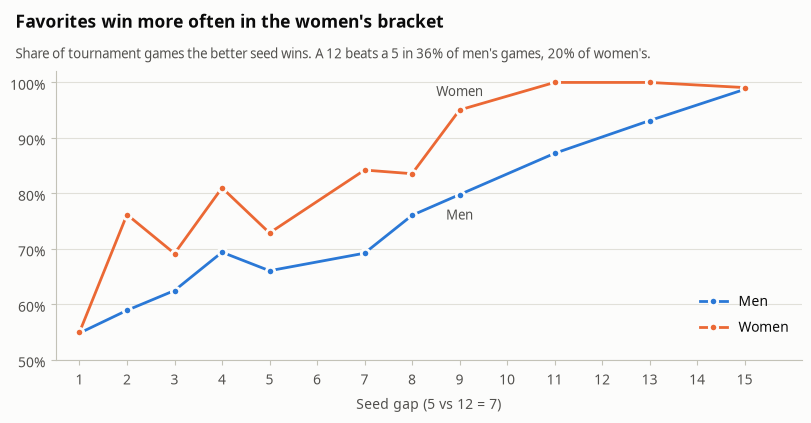

In [3]:
rows = []
for p in "MW":
    seeds = mania.read(f"{p}NCAATourneySeeds")
    seed = seeds.set_index(["Season", "TeamID"]).Seed.str[1:3].astype(int)
    t = mania.read(f"{p}NCAATourneyCompactResults")
    ws = seed.reindex(list(zip(t.Season, t.WTeamID))).values
    ls = seed.reindex(list(zip(t.Season, t.LTeamID))).values
    rows.append(pd.DataFrame({"gender": p, "win_seed": ws, "lose_seed": ls})[ws != ls])
games = pd.concat(rows)
games["gap"] = (games.win_seed - games.lose_seed).abs()
games["fav_won"] = games.win_seed < games.lose_seed

by_gap = games.groupby(["gender", "gap"]).fav_won.agg(["mean", "size"]).reset_index().query("size >= 30")
five_twelve = games[games[["win_seed", "lose_seed"]].min(axis=1).eq(5) & games[["win_seed", "lose_seed"]].max(axis=1).eq(12)]
upset_512 = (five_twelve.win_seed == 12).groupby(five_twelve.gender).mean()
display(games.groupby("gender").fav_won.mean().rename("better seed wins").to_frame().T)


def draw(fig, c):
    ax = fig.subplots()
    for p in "MW":
        d = by_gap[by_gap.gender == p]
        ax.plot(d.gap, d["mean"], color=c[p], marker="o", ms=6, mec=c["surface"], mew=2, label=NAME[p])
        at = d[d.gap == 9].iloc[0]
        ax.annotate(NAME[p], (9, at["mean"]), xytext=(0, 10 if p == "W" else -18), textcoords="offset points",
                    ha="center", color=c["ink2"], fontsize=9.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(ylim=(0.5, 1.02), xlim=(0.5, 16.2), xticks=range(1, 16), xlabel="Seed gap (5 vs 12 = 7)")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right", bbox_to_anchor=(1, 0.04))
    titles(fig, c, "Favorites win more often in the women's bracket",
           f"Share of tournament games the better seed wins. A 12 beats a 5 in {upset_512['M']:.0%} of men's games, "
           f"{upset_512['W']:.0%} of women's.")


show("upsets", draw)

The better seed wins 72% of men's games and 78% of women's, and the gap holds at almost every seed difference. **Men and women get separate models**, and the women's score should come out much lower.

### 1.2 Does home court matter?

In [4]:
for p in "MW":
    rs = mania.read(f"{p}RegularSeasonCompactResults")
    sited = rs[rs.WLoc != "N"]
    print(f"{NAME[p]:6s} home teams win {(sited.WLoc == 'H').mean():.0%} of regular-season games not at a neutral site")
print(f"Elo home bonus of {mania.ELO_HCA:.0f} points = {1 / (1 + 10 ** (-mania.ELO_HCA / 400)):.0%} win chance between equal teams")

Men    home teams win 66% of regular-season games not at a neutral site
Women  home teams win 61% of regular-season games not at a neutral site
Elo home bonus of 65 points = 59% win chance between equal teams


Yes. Every tournament game is at a neutral site, but most of the season isn't, so a team's record partly reflects where it played. The Elo rating gives the home team a 65-point head start in its expectation. A road win then moves the rating more than a home win.

### 1.3 How far back does each data source go?

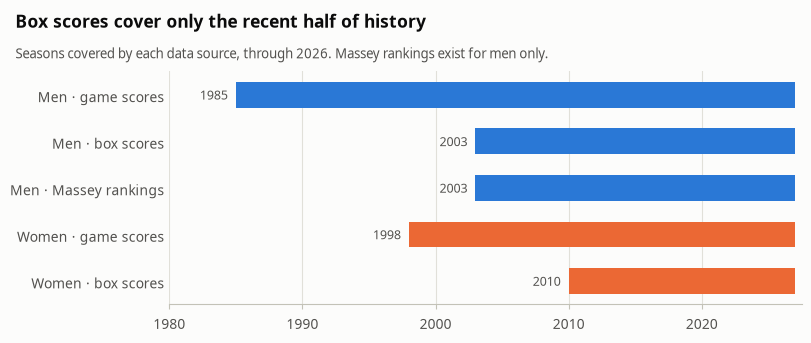

In [5]:
season_range = lambda name: pd.read_csv(mania.DATA_DIR / f"{name}.csv", usecols=["Season"]).Season.agg(["min", "max"])
coverage = pd.DataFrame([
    ("M", "Men · game scores", *season_range("MRegularSeasonCompactResults")),
    ("M", "Men · box scores", *season_range("MRegularSeasonDetailedResults")),
    ("M", "Men · Massey rankings", *season_range("MMasseyOrdinals")),
    ("W", "Women · game scores", *season_range("WRegularSeasonCompactResults")),
    ("W", "Women · box scores", *season_range("WRegularSeasonDetailedResults")),
], columns=["gender", "source", "first", "last"])


def draw(fig, c):
    ax = fig.subplots()
    y = np.arange(len(coverage))[::-1]
    ax.barh(y, coverage["last"] - coverage["first"] + 1, left=coverage["first"], height=0.55,
            color=[c[g] for g in coverage.gender])
    for yi, first in zip(y, coverage["first"]):
        ax.text(first - 0.6, yi, str(first), ha="right", va="center", color=c["ink2"], fontsize=9)
    ax.set(yticks=y, yticklabels=coverage.source, xlim=(1980, 2027.5))
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="y", visible=False)
    titles(fig, c, "Box scores cover only the recent half of history",
           "Seasons covered by each data source, through 2026. Massey rankings exist for men only.")


show("coverage", draw, size=(8, 3.4))

Before 2003 (men) and 2010 (women), the box-score features are filled with an average, so every A-minus-B difference is zero. In those seasons the model has to rely on what can be computed from final scores alone: Elo, SRS, margin and win %. Those ratings had better be strong. Are they?

### 1.4 Which signals separate winners from losers?

Every tournament game becomes one row of **A-minus-B differences**: Elo of A minus Elo of B, and so on for every feature. That makes each row the same game no matter which team is listed first. Before any model, how well does each difference *alone* rank the winners?

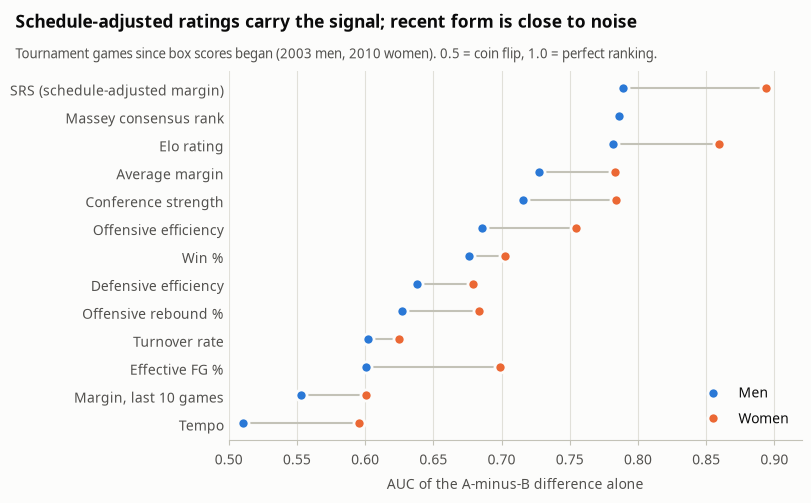

In [6]:
T = {}
for p in "MW":
    f = mania.team_features(p)
    X, y, g, m = mania.tourney_games(p, f)
    T[p] = dict(X=X, y=y, g=g, m=m, era=g >= (2003 if p == "M" else 2010))

NICE = {
    "SRS": "SRS (schedule-adjusted margin)", "Massey": "Massey consensus rank", "Elo": "Elo rating",
    "ConfSRS": "Conference strength", "Margin": "Average margin", "WinPct": "Win %",
    "OffEff": "Offensive efficiency", "DefEff": "Defensive efficiency", "eFG": "Effective FG %",
    "ORB": "Offensive rebound %", "TOV": "Turnover rate", "RecentMargin": "Margin, last 10 games",
    "Tempo": "Tempo",
}
auc = pd.DataFrame({
    p: {k: (lambda a: max(a, 1 - a))(roc_auc_score(t["y"][t["era"]], t["X"].loc[t["era"], f"D_{k}"]))
        for k in NICE if f"D_{k}" in t["X"]}
    for p, t in T.items()
}).sort_values("M")


def draw(fig, c):
    ax = fig.subplots()
    y = np.arange(len(auc))
    ax.hlines(y, auc.min(axis=1), auc.max(axis=1), color=c["neutral"], lw=1.5)
    for p in "MW":
        ax.plot(auc[p], y, "o", ms=8, color=c[p], mec=c["surface"], mew=2, label=NAME[p], ls="none")
    ax.set(yticks=y, yticklabels=[NICE[k] for k in auc.index], xlim=(0.5, 0.92), xlabel="AUC of the A-minus-B difference alone")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    titles(fig, c, "Schedule-adjusted ratings carry the signal; recent form is close to noise",
           "Tournament games since box scores began (2003 men, 2010 women). 0.5 = coin flip, 1.0 = perfect ranking.")


show("signal", draw, size=(8, 5))

The three best signals, SRS, Massey and Elo, all **correct for who you played**. Raw efficiency stats rank well below them. "Hot team" momentum, the margin over the last 10 games, is close to a coin flip (0.55 for men).

### 1.5 Are the top signals telling us different things?

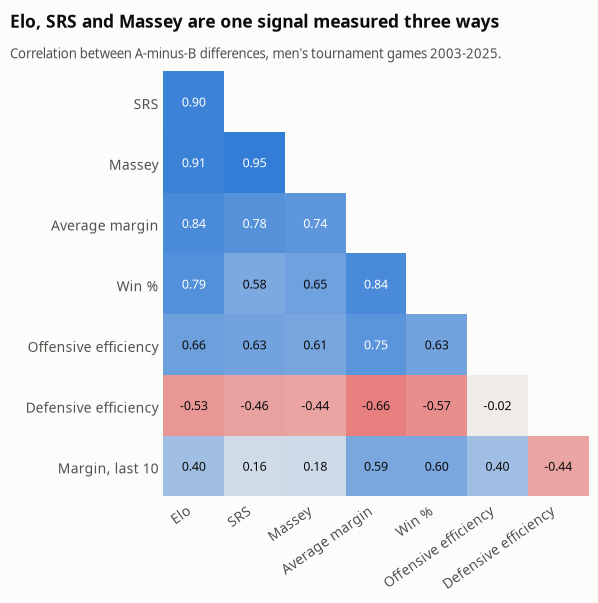

In [7]:
SHORT = {"SRS": "SRS", "Massey": "Massey", "Elo": "Elo", "RecentMargin": "Margin, last 10"}
cols = ["Elo", "SRS", "Massey", "Margin", "WinPct", "OffEff", "DefEff", "RecentMargin"]
corr = T["M"]["X"].loc[T["M"]["era"], [f"D_{k}" for k in cols]].corr().to_numpy(copy=True)
corr[np.triu_indices_from(corr)] = np.nan


def draw(fig, c):
    ax = fig.subplots()
    cmap = LinearSegmentedColormap.from_list("div", [c["red"], c["mid"], c["M"]])
    ax.imshow(corr[1:, :-1], cmap=cmap, vmin=-1, vmax=1)
    labels = [SHORT.get(k, NICE[k]) for k in cols]
    for i in range(1, len(cols)):
        for j in range(i):
            r = corr[i, j]
            ax.text(j, i - 1, f"{r:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(r) > 0.7 and c["surface"] == THEMES["light"]["surface"] else c["ink"])
    ax.set(xticks=range(len(cols) - 1), yticks=range(len(cols) - 1))
    ax.set_xticklabels(labels[:-1], rotation=35, ha="right")
    ax.set_yticklabels(labels[1:])
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    titles(fig, c, "Elo, SRS and Massey are one signal measured three ways",
           "Correlation between A-minus-B differences, men's tournament games 2003-2025.")


show("redundancy", draw, size=(7.5, 6))

Elo, SRS and Massey correlate at 0.90-0.95. Adding a fourth rating system won't add much. What helps is a model that can **weigh correlated signals without overreacting to any one**, which is what a regularized logistic regression does.

## 2. The model

```
regular-season games ──► team-season features ──► A-minus-B differences ──┬─► logistic regression ─┐
 (Elo, SRS, Massey, box-score rates, conference, recent form)              ├─► gradient boosting ────┼─► weighted blend ─► clip [0.01, 0.99]
                                                                           └─► raw Elo probability ──┘
```

Everything is evaluated **out-of-fold by season**: five folds of whole seasons, so a tournament is never predicted by a model that trained on it. The blend weights are a grid search over those out-of-fold predictions. For comparison I add the obvious baseline the model can't use: **a logistic regression on seed difference alone**.

In [8]:
def seed_baseline(p, t):
    seed = mania.read(f"{p}NCAATourneySeeds").set_index(["Season", "TeamID"]).Seed.str[1:3].astype(int)
    games = mania.read(f"{p}NCAATourneyCompactResults")
    a, b = games[["WTeamID", "LTeamID"]].min(axis=1), games[["WTeamID", "LTeamID"]].max(axis=1)
    diff = pd.DataFrame({"d": seed.reindex(list(zip(games.Season, a))).values - seed.reindex(list(zip(games.Season, b))).values})
    oof = np.zeros(len(diff))
    for tr, va in GroupKFold(n_splits=5).split(diff, t["y"], t["g"]):
        oof[va] = LogisticRegression().fit(diff.iloc[tr], t["y"].iloc[tr]).predict_proba(diff.iloc[va])[:, 1]
    return oof


MODELS = {"seed": "Seeds only (baseline)", "elo": "Raw Elo probability", "hgb": "Gradient boosting",
          "logit": "Logistic regression", "blend": "Blend (submitted)"}
for p, t in T.items():
    t["model"] = mania.fit(t["X"], t["y"], t["g"], t["m"])
    t["oof"] = t["model"]["oof"].assign(seed=seed_baseline(p, t))

scores = pd.DataFrame({NAME[p]: {MODELS[k]: brier_score_loss(t["y"], t["oof"][k]) for k in MODELS} for p, t in T.items()})
weights = pd.DataFrame({NAME[p]: dict(zip(["logistic", "boosting", "Elo"], np.round(t["model"]["weights"], 2)))
                        for p, t in T.items()})
display(scores.style.format("{:.4f}").set_caption("Out-of-fold Brier score (lower is better)"))
display(weights.T.style.format("{:.2f}").set_caption("Blend weights chosen by out-of-fold Brier"))

,Men,Women
Seeds only (baseline),0.1901,0.1503
Raw Elo probability,0.1902,0.1592
Gradient boosting,0.1949,0.1543
Logistic regression,0.1823,0.1403
Blend (submitted),0.1821,0.1400


,logistic,boosting,Elo
Men,0.85,0.00,0.15
Women,0.90,0.00,0.10


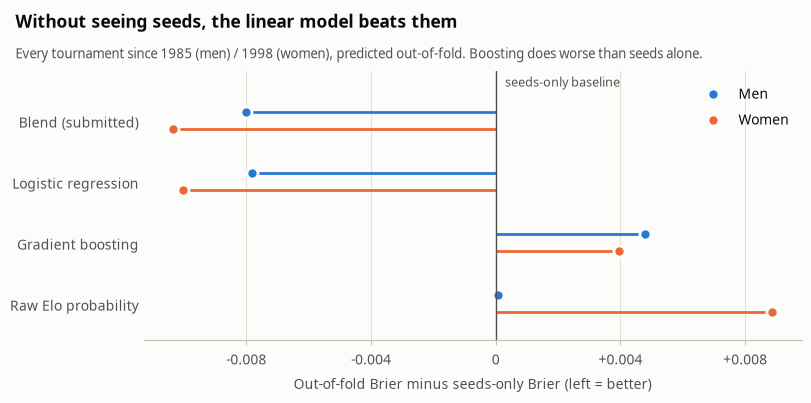

In [9]:
delta = scores.drop(index=MODELS["seed"]).sub(scores.loc[MODELS["seed"]], axis=1)


def draw(fig, c):
    ax = fig.subplots()
    y = np.arange(len(delta))
    for k, p in enumerate("MW"):
        yy = y + (0.14 if p == "M" else -0.14)
        ax.hlines(yy, 0, delta[NAME[p]], color=c[p], lw=2)
        ax.plot(delta[NAME[p]], yy, "o", ms=8, color=c[p], mec=c["surface"], mew=2, label=NAME[p], ls="none")
    ax.axvline(0, color=c["ink2"], lw=1)
    ax.text(0.0003, len(delta) - 0.45, "seeds-only baseline", color=c["ink2"], fontsize=9)
    ax.set(yticks=y, yticklabels=delta.index, xlabel="Out-of-fold Brier minus seeds-only Brier (left = better)",
           ylim=(-0.6, len(delta) - 0.2))
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(MultipleLocator(0.004))
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.3f}" if abs(v) > 1e-9 else "0")
    ax.legend(loc="upper right")
    titles(fig, c, "Without seeing seeds, the linear model beats them",
           "Every tournament since 1985 (men) / 1998 (women), predicted out-of-fold. Boosting does worse than seeds alone.")


show("ablation", draw, size=(8, 4))

Three findings, all different from what I would have guessed going in:

- **Logistic regression does nearly all the work.** It beats the seeds-only model by about 0.008 (men) and 0.010 (women) without ever seeing a seed.
- **Gradient boosting is worse than seeds alone**, and the blend gives it zero weight. With a few thousand noisy games, trees overfit what a linear model averages away.
- **Raw Elo earns its 10-15% share** because it is a prediction that involves no fitting at all. It pulls the blend gently toward a sane prior.

### 2.1 Can the probabilities be taken at face value?

Brier score rewards *calibration*, not just picking winners. When the model says 80%, the favorite should win about 80% of the time.

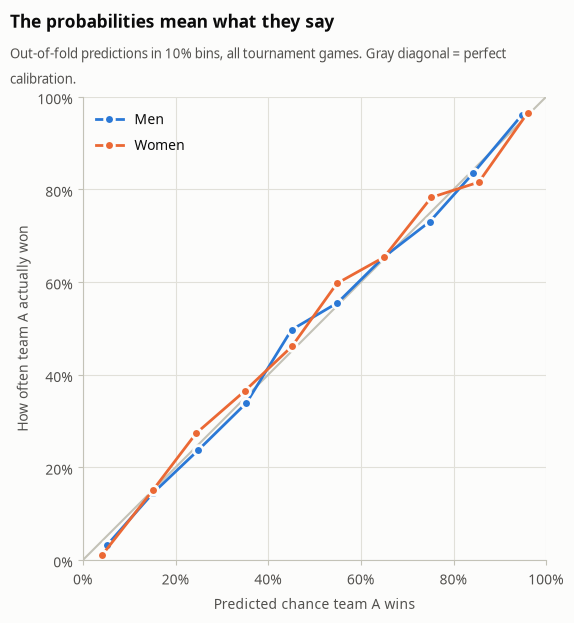

gender,Men,Women
games per bin,,
"(-0.001, 0.1]",152.0,265.0
"(0.1, 0.2]",202.0,152.0
"(0.2, 0.3]",278.0,150.0
"(0.3, 0.4]",286.0,129.0
"(0.4, 0.5]",310.0,128.0
"(0.5, 0.6]",337.0,129.0
"(0.6, 0.7]",321.0,153.0
"(0.7, 0.8]",297.0,138.0
"(0.8, 0.9]",225.0,179.0


In [10]:
calib = []
for p, t in T.items():
    d = pd.DataFrame({"p": t["oof"]["blend"], "y": t["y"]})
    d["bin"] = pd.cut(d.p, np.linspace(0, 1, 11), include_lowest=True)
    calib.append(d.groupby("bin", observed=True).agg(pred=("p", "mean"), won=("y", "mean"), n=("y", "size")).assign(gender=p))
calib = pd.concat(calib)


def draw(fig, c):
    ax = fig.subplots()
    ax.plot([0, 1], [0, 1], color=c["neutral"], lw=1.5)
    for p in "MW":
        d = calib[calib.gender == p]
        ax.plot(d.pred, d.won, color=c[p], marker="o", ms=7, mec=c["surface"], mew=2, label=NAME[p])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="Predicted chance team A wins", ylabel="How often team A actually won")
    ax.legend(loc="upper left")
    titles(fig, c, "The probabilities mean what they say",
           "Out-of-fold predictions in 10% bins, all tournament games. Gray diagonal = perfect calibration.")


show("calibration", draw, size=(6, 6.2))
display(calib.pivot_table(index="bin", columns="gender", values="n", observed=True).rename(columns=NAME).rename_axis("games per bin"))

Both curves track the diagonal. With 130-340 games per bin, a few points of wobble is just noise. Clipping to [1%, 99%] changes the historical score by less than 0.00001; it's insurance against a once-a-decade upset, not an edge.

### 2.2 How much is skill, and how much is the bracket?

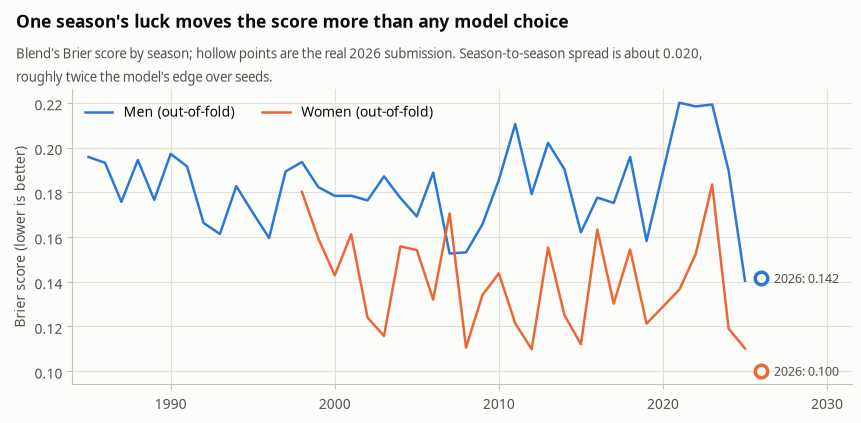

In [11]:
submitted = pd.read_csv("results/submitted_2026.csv")
actual = pd.read_csv("results/actual_2026.csv").merge(submitted, on="ID")
actual["gender"] = np.where(actual.ID.str[5] == "1", "M", "W")
live = actual.groupby("gender").apply(lambda d: brier_score_loss(d.LowerIdWon, d.Pred), include_groups=False)

per_season = pd.DataFrame({
    p: pd.DataFrame({"y": t["y"], "p": t["oof"]["blend"], "s": t["g"]}).groupby("s")
         .apply(lambda d: brier_score_loss(d.y, d.p), include_groups=False)
    for p, t in T.items()
})


def draw(fig, c):
    ax = fig.subplots()
    for p in "MW":
        s = per_season[p].dropna()
        ax.plot(s.index, s.values, color=c[p], lw=1.8, label=f"{NAME[p]} (out-of-fold)")
        ax.plot(2026, live[p], "o", ms=9, mfc=c["surface"], mec=c[p], mew=2.5)
        ax.annotate(f"2026: {live[p]:.3f}", (2026, live[p]), xytext=(9, 0), textcoords="offset points",
                    va="center", color=c["ink2"], fontsize=9)
    ax.set(xlim=(1984, 2031.5), ylabel="Brier score (lower is better)")
    ax.legend(loc="upper left", ncols=2)
    titles(fig, c, "One season's luck moves the score more than any model choice",
           f"Blend's Brier score by season; hollow points are the real 2026 submission. Season-to-season spread is about {per_season.std().mean():.3f}, roughly twice "
           f"the model's edge over seeds.")


show("by_season", draw, size=(8.5, 4.2))

The same model scores anywhere from 0.14 to 0.22 on the men's side depending on the year. A 0.009 edge over seeds is real, since it holds across 40 seasons, but a single tournament can easily hide or double it. **Leaderboard rank in any one year is partly luck**, which is why everything above is measured across all seasons rather than on one leaderboard.

## 3. 2026, for real

`results/submitted_2026.csv` is the exact file I submitted. `results/actual_2026.csv` holds the 126 scored games (63 per bracket; the First Four isn't scored). The first check: does it reproduce Kaggle's number?

In [12]:
lb = pd.read_csv("results/leaderboard_2026.csv")
KAGGLE = 0.1208707  # private leaderboard score for this file
score = brier_score_loss(actual.LowerIdWon, actual.Pred)
rank = int((lb.Score < KAGGLE).sum() + 1)
print(f"Brier on the 126 games: {score:.7f}  (Kaggle private leaderboard: {KAGGLE})")
print(f"Men {live['M']:.4f} · Women {live['W']:.4f} · rank {rank} of {len(lb):,} (top {rank / len(lb):.1%})")

Brier on the 126 games: 0.1208708  (Kaggle private leaderboard: 0.1208707)
Men 0.1416 · Women 0.1001 · rank 29 of 3,462 (top 0.8%)


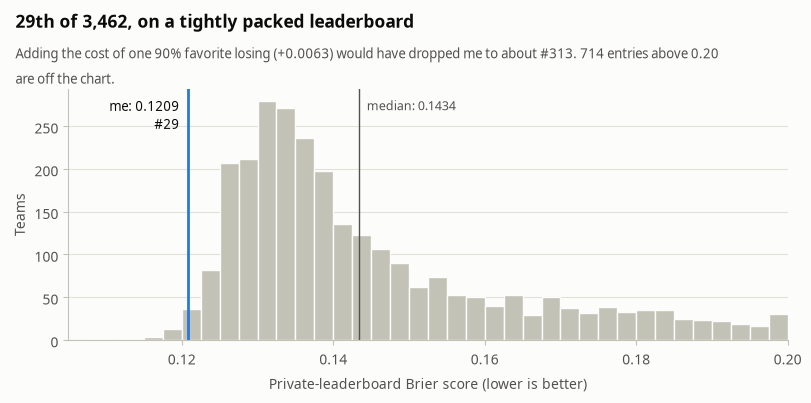

In [13]:
one_upset = (0.9 ** 2 - 0.1 ** 2) / len(actual)
rank_plus = int((lb.Score < KAGGLE + one_upset).sum() + 1)
shown = lb[lb.Score.between(0.105, 0.20)]


def draw(fig, c):
    ax = fig.subplots()
    ax.hist(shown.Score, bins=np.arange(0.105, 0.2001, 0.0025), color=c["neutral"], edgecolor=c["surface"], linewidth=1)
    ax.axvline(KAGGLE, color=c["M"], lw=2)
    ax.text(KAGGLE - 0.0012, ax.get_ylim()[1] * 0.97, f"me: {KAGGLE:.4f}\n#{rank}", color=c["ink"], ha="right", va="top", fontsize=9.5)
    med = lb.Score.median()
    ax.axvline(med, color=c["ink2"], lw=1)
    ax.text(med + 0.001, ax.get_ylim()[1] * 0.97, f"median: {med:.4f}", color=c["ink2"], va="top", fontsize=9)
    ax.set(xlabel="Private-leaderboard Brier score (lower is better)", ylabel="Teams", xlim=(0.105, 0.20))
    ax.grid(axis="x", visible=False)
    titles(fig, c, f"29th of {len(lb):,}, on a tightly packed leaderboard",
           f"Adding the cost of one 90% favorite losing (+{one_upset:.4f}) would have dropped me to about #{rank_plus}. "
           f"{(lb.Score > 0.20).sum()} entries above 0.20 are off the chart.")


show("leaderboard", draw, size=(8, 4))

In [14]:
names = pd.concat([mania.read("MTeams"), mania.read("WTeams")]).set_index("TeamID").TeamName
seeds = pd.concat([mania.read(f"{p}NCAATourneySeeds") for p in "MW"]).query("Season == 2026")
seed = seeds.set_index("TeamID").Seed.str[1:3].astype(int)

ids = actual.ID.str.split("_", expand=True).astype(int)
won_low = actual.LowerIdWon == 1
winner, loser = ids[1].where(won_low, ids[2]), ids[2].where(won_low, ids[1])
games26 = pd.DataFrame({
    "Bracket": actual.gender.map(NAME),
    "Winner": [f"({seed[t]}) {names[t]}" for t in winner],
    "Loser": [f"({seed[t]}) {names[t]}" for t in loser],
    "Model's chance for the winner": actual.Pred.where(won_low, 1 - actual.Pred),
    "Brier cost": (actual.Pred - actual.LowerIdWon) ** 2,
})
fmt = {"Model's chance for the winner": "{:.0%}", "Brier cost": "{:.3f}"}
saw_it = games26[(winner.map(seed) > loser.map(seed)).values & (games26["Model's chance for the winner"] > 0.5)]
display(saw_it.sort_values("Model's chance for the winner", ascending=False).style.format(fmt).hide()
        .set_caption("Seed upsets the model called (winner had the worse seed, model still favored it)"))
display(games26.nlargest(6, "Brier cost").style.format(fmt).hide().set_caption("Costliest misses"))
worst10 = games26["Brier cost"].nlargest(10).sum() / games26["Brier cost"].sum()
print(f"The 10 costliest games out of 126 account for {worst10:.0%} of the total Brier loss.")

Bracket,Winner,Loser,Model's chance for the winner,Brier cost
Women,(9) USC,(8) Clemson,85%,0.023
Men,(9) Utah St,(8) Villanova,60%,0.162
Men,(5) St John's,(4) Kansas,56%,0.195
Men,(9) St Louis,(8) Georgia,55%,0.198
Men,(3) Illinois,(2) Houston,53%,0.219
Men,(9) Iowa,(8) Clemson,52%,0.226
Men,(6) Tennessee,(3) Virginia,52%,0.228


Bracket,Winner,Loser,Model's chance for the winner,Brier cost
Women,(10) Virginia,(2) Iowa,10%,0.809
Men,(9) Iowa,(1) Florida,19%,0.660
Men,(11) Texas,(3) Gonzaga,24%,0.576
Men,(10) Texas A&M,(7) St Mary's CA,28%,0.519
Men,(12) High Point,(5) Wisconsin,28%,0.518
Men,(2) Connecticut,(1) Duke,31%,0.472


The 10 costliest games out of 126 account for 35% of the total Brier loss.
